In [4]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [5]:
import pandas as pd
import os

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Create the data folder if it doesn't exist
os.makedirs("../data", exist_ok=True)

# Save the dataset as CSV
df.to_csv("../data/cleveland.csv", index=False)

print("Dataset saved successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset saved successfully!
Shape: (303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  


In [6]:
# EDA setup and data preparation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (9, 5)

# Work on a copy so the original fetched DataFrame remains unchanged.
eda_df = df.copy()
eda_df.columns = eda_df.columns.astype(str).str.strip()

# The UCI Cleveland dataset can contain '?' strings for missing values.
eda_df = eda_df.replace("?", np.nan)

# Convert columns to numeric where possible.
for column in eda_df.columns:
    eda_df[column] = pd.to_numeric(eda_df[column], errors="ignore")

print("Dataset shape:", eda_df.shape)
print("\nColumn names:")
print(eda_df.columns.tolist())

print("\nData types:")
display(eda_df.dtypes.to_frame("Data type"))

print("\nFirst five rows:")
display(eda_df.head())


Dataset shape: (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types:


/tmp/ipykernel_1765474/73715547.py:19: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  eda_df[column] = pd.to_numeric(eda_df[column], errors="ignore")


,Data type
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64



First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [8]:
display(eda_df.describe(include="all").T)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


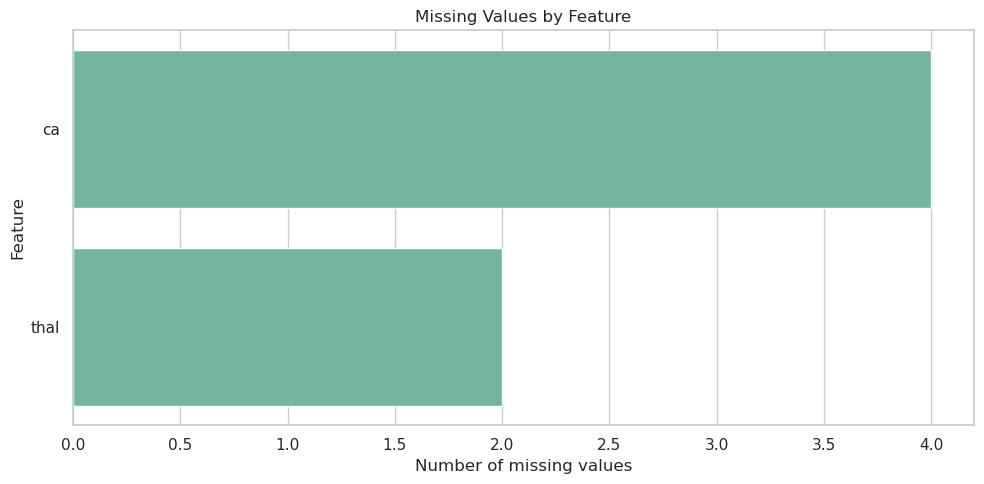

In [9]:
missing_counts = eda_df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]

if missing_counts.empty:
    print("No missing values found in the dataset.")
else:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_counts.values, y=missing_counts.index)
    plt.title("Missing Values by Feature")
    plt.xlabel("Number of missing values")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_1765474/381730375.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["0 - No disease", "1 - Disease"])


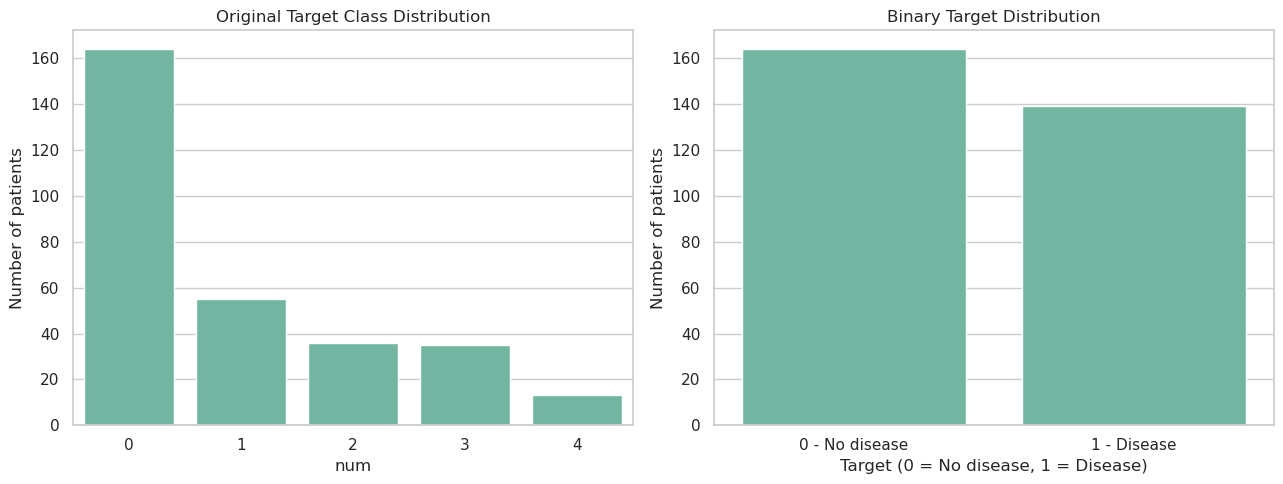

In [10]:
target_column = "num" if "num" in eda_df.columns else (
    "target" if "target" in eda_df.columns else None
)

if target_column is None:
    print("Target column not found. Expected 'num' or 'target'.")
else:
    target_values = pd.to_numeric(eda_df[target_column], errors="coerce")
    target_data = eda_df.loc[target_values.notna()].copy()
    target_data[target_column] = target_values.dropna()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.countplot(
        data=target_data,
        x=target_column,
        order=sorted(target_data[target_column].unique()),
        ax=axes[0]
    )
    axes[0].set_title("Original Target Class Distribution")
    axes[0].set_xlabel(target_column)
    axes[0].set_ylabel("Number of patients")

    target_data["binary_target"] = (target_data[target_column] > 0).astype(int)
    sns.countplot(
        data=target_data,
        x="binary_target",
        order=[0, 1],
        ax=axes[1]
    )
    axes[1].set_title("Binary Target Distribution")
    axes[1].set_xlabel("Target (0 = No disease, 1 = Disease)")
    axes[1].set_ylabel("Number of patients")
    axes[1].set_xticklabels(["0 - No disease", "1 - Disease"])

    plt.tight_layout()
    plt.show()


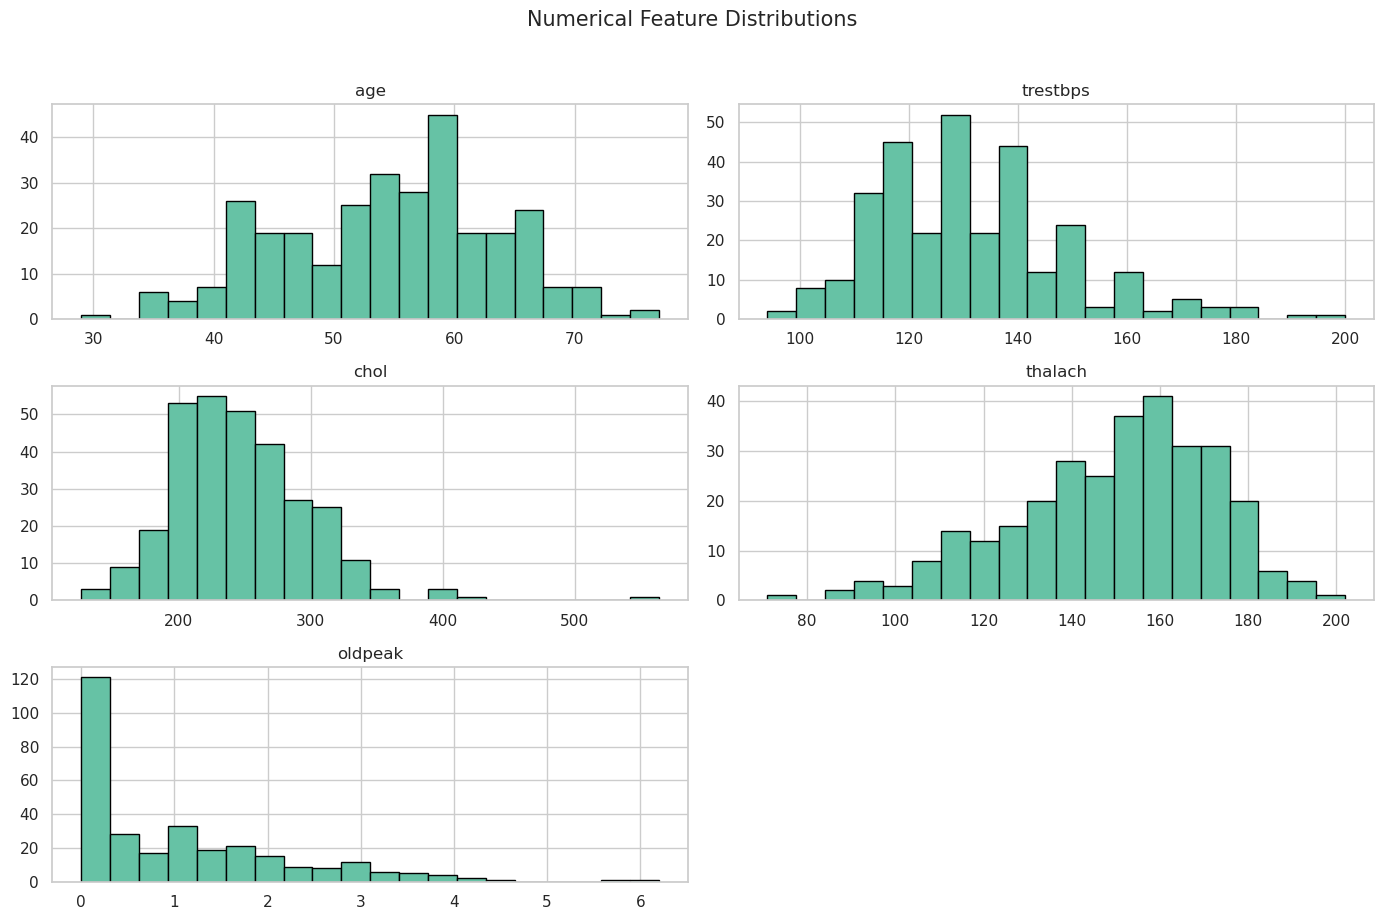

In [11]:
numeric_features = [
    column for column in
    ["age", "trestbps", "chol", "thalach", "oldpeak"]
    if column in eda_df.columns
]

if numeric_features:
    eda_df[numeric_features] = eda_df[numeric_features].apply(
        pd.to_numeric, errors="coerce"
    )
    eda_df[numeric_features].hist(
        bins=20,
        figsize=(14, 9),
        edgecolor="black"
    )
    plt.suptitle("Numerical Feature Distributions", y=1.02, fontsize=15)
    plt.tight_layout()
    plt.show()
else:
    print("No expected numerical features were found.")


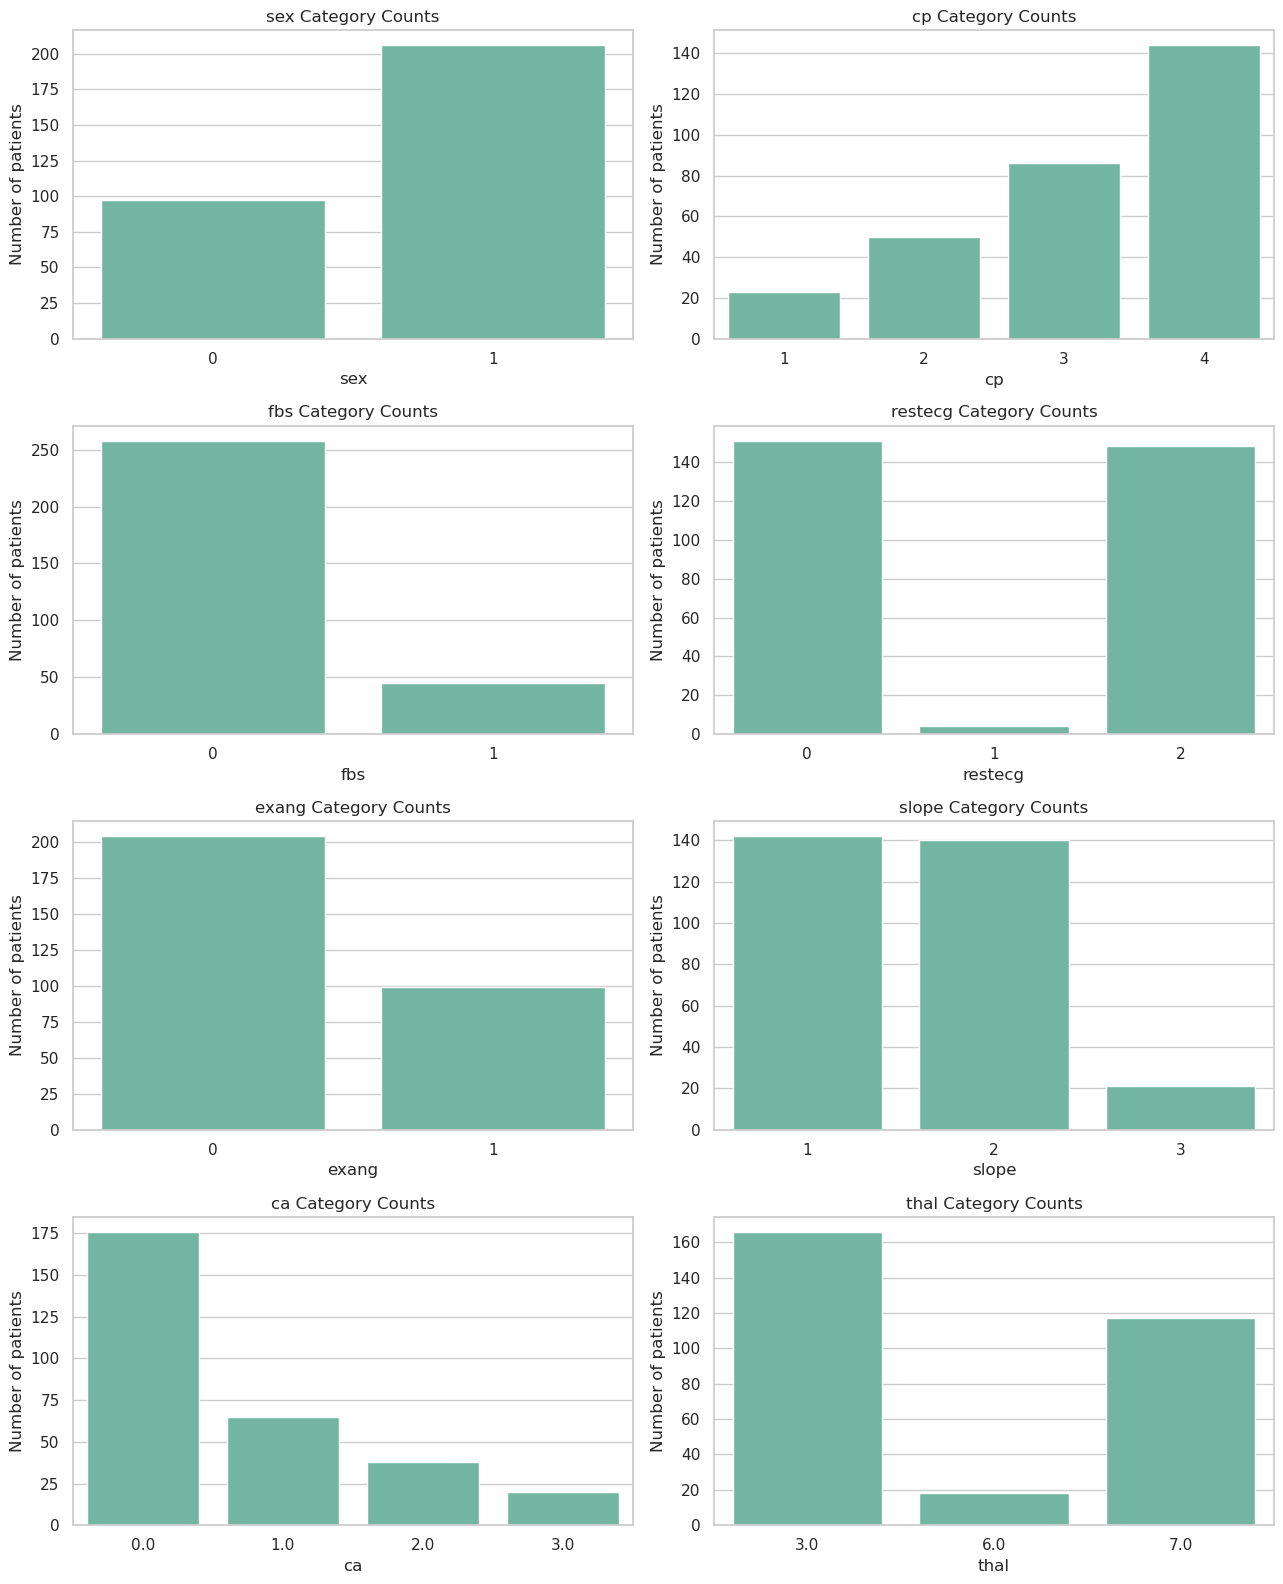

In [12]:
categorical_features = [
    column for column in
    ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
    if column in eda_df.columns
]

if categorical_features:
    ncols = 2
    nrows = int(np.ceil(len(categorical_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, feature in zip(axes, categorical_features):
        plot_data = eda_df[feature].dropna()
        sns.countplot(
            x=plot_data,
            order=sorted(plot_data.unique()),
            ax=ax
        )
        ax.set_title(f"{feature} Category Counts")
        ax.set_xlabel(feature)
        ax.set_ylabel("Number of patients")

    for ax in axes[len(categorical_features):]:
        ax.remove()

    plt.tight_layout()
    plt.show()
else:
    print("No expected categorical features were found.")


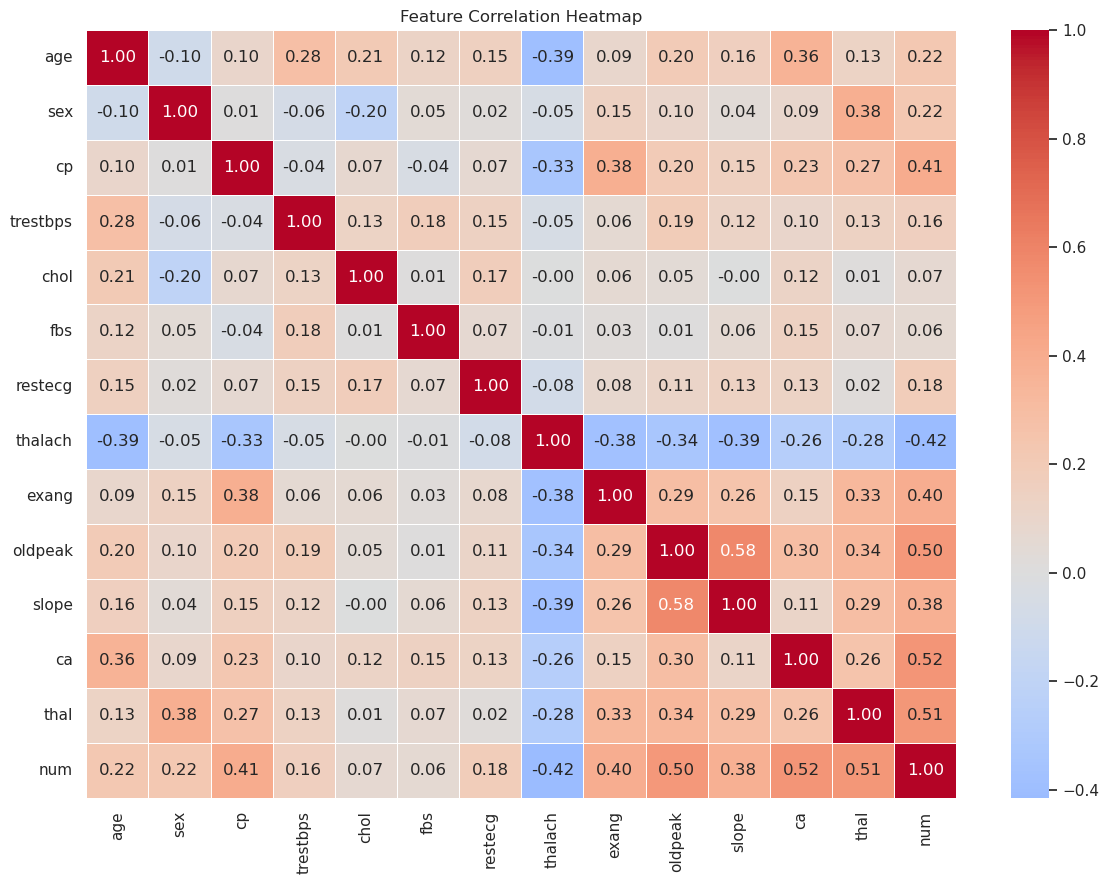

In [13]:
correlation_data = eda_df.select_dtypes(include=np.number).copy()

if correlation_data.shape[1] >= 2:
    plt.figure(figsize=(12, 9))
    correlation_matrix = correlation_data.corr()
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )
    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns to calculate correlations.")
